# BÀI THỰC HÀNH LAB 1: KHAI PHÁ DỮ LIỆU
- **Học phần:** Khai phá dữ liệu (Data Mining)
- **Họ và tên sinh viên:** Vi Duy Đoàn
- **Mã số sinh viên (MSSV):** 6451071020
- **Lớp:** Khai phá dữ liệu
- **Bài 1:** Khảo sát, trực quan hóa và tiền xử lý tập dữ liệu Titanic (Tương ứng Bài 2 Trang 15-17)

---

## Câu 1: Đọc tập dữ liệu Titanic và khám phá tổng quan
**Yêu cầu:** Import thư viện (numpy, pandas, seaborn, matplotlib). Đọc file `titanic.csv`, hiển thị `df.head(12)`, `df.info()`, `df.describe()`.

In [1]:
print("Vi Duy Đoàn - 6451071020")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import re

# Đọc file titanic.csv (tự động tải từ OpenML nếu chưa tồn tại)
if not os.path.exists('titanic.csv'):
    from sklearn.datasets import fetch_openml
    data = fetch_openml('titanic', version=1, as_frame=True)
    df = data.frame
    df.to_csv('titanic.csv', index=False)

df = pd.read_csv('titanic.csv')

# 1. Hiển thị 12 dòng đầu tiên
print("=== 12 DÒNG ĐẦU TIÊN CỦA TẬP DỮ LIỆU (df.head(12)) ===")
display(df.head(12))

# 2. Hiển thị thông tin cấu trúc và kiểu dữ liệu
print("\n=== THÔNG TIN CẤU TRÚC VÀ KIỂU DỮ LIỆU (df.info()) ===")
df.info()

# 3. Thống kê mô tả các thuộc tính số
print("\n=== BẢNG THỐNG KÊ MÔ TẢ CÁC THUỘC TÍNH SỐ (df.describe()) ===")
display(df.describe())


Vi Duy Đoàn - 6451071020


=== 12 DÒNG ĐẦU TIÊN CỦA TẬP DỮ LIỆU (df.head(12)) ===


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
5,1,1,"Anderson, Mr. Harry",male,48.0000,0,0,19952,26.5500,E12,S,3,NaN,"New York, NY"
6,1,1,"Andrews, Miss. Kornelia Theodosia",female,63.0000,1,0,13502,77.9583,D7,S,10,NaN,"Hudson, NY"
7,1,0,"Andrews, Mr. Thomas Jr",male,39.0000,0,0,112050,0.0000,A36,S,NaN,NaN,"Belfast, NI"
8,1,1,"Appleton, Mrs. Edward Dale (Charlotte Lamson)",female,53.0000,2,0,11769,51.4792,C101,S,D,NaN,"Bayside, Queens, NY"
9,1,0,"Artagaveytia, Mr. Ramon",male,71.0000,0,0,PC 17609,49.5042,NaN,C,NaN,22.0,"Montevideo, Uruguay"



=== THÔNG TIN CẤU TRÚC VÀ KIỂU DỮ LIỆU (df.info()) ===
<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pclass     1309 non-null   int64  
 1   survived   1309 non-null   int64  
 2   name       1309 non-null   str    
 3   sex        1309 non-null   str    
 4   age        1046 non-null   float64
 5   sibsp      1309 non-null   int64  
 6   parch      1309 non-null   int64  
 7   ticket     1309 non-null   str    
 8   fare       1308 non-null   float64
 9   cabin      295 non-null    str    
 10  embarked   1307 non-null   str    
 11  boat       486 non-null    str    
 12  body       121 non-null    float64
 13  home.dest  745 non-null    str    
dtypes: float64(3), int64(4), str(7)
memory usage: 143.3 KB

=== BẢNG THỐNG KÊ MÔ TẢ CÁC THUỘC TÍNH SỐ (df.describe()) ===


,pclass,survived,age,sibsp,parch,fare,body
count,1309.000000,1309.000000,1046.000000,1309.000000,1309.000000,1308.000000,121.000000
mean,2.294882,0.381971,29.881135,0.498854,0.385027,33.295479,160.809917
std,0.837836,0.486055,14.413500,1.041658,0.865560,51.758668,97.696922
min,1.000000,0.000000,0.166700,0.000000,0.000000,0.000000,1.000000
25%,2.000000,0.000000,21.000000,0.000000,0.000000,7.895800,72.000000
50%,3.000000,0.000000,28.000000,0.000000,0.000000,14.454200,155.000000
75%,3.000000,1.000000,39.000000,1.000000,0.000000,31.275000,256.000000
max,3.000000,1.000000,80.000000,8.000000,9.000000,512.329200,328.000000


### Nhận xét Câu 1:
1. **Kích thước tập dữ liệu:** Tập dữ liệu có **1309 dòng** (mỗi dòng tương ứng 1 hành khách) và **14 cột** (thuộc tính).
2. **Các kiểu dữ liệu trong bảng:**
   - **Số nguyên (`int64`):** `pclass` (hạng vé: 1, 2, 3), `survived` (nhãn sống sót: 0 = tử vong, 1 = sống sót), `sibsp` (số anh chị em/vợ chồng đi cùng), `parch` (số cha mẹ/con cái đi cùng).
   - **Số thực (`float64`):** `age` (tuổi), `fare` (giá vé), `body` (mã định danh thi thể tìm thấy).
   - **Chuỗi ký tự / Phân loại (`str` / `object`):** `name`, `sex`, `ticket`, `cabin`, `embarked`, `boat`, `home.dest`.
3. **Phát hiện ban đầu về giá trị thiếu (missing values):**
   - Cột `age` chỉ có 1046 giá trị hợp lệ (thiếu 263 giá trị ~ 20.1%).
   - Cột `fare` thiếu 1 giá trị.
   - Các cột `cabin`, `boat`, `body`, `home.dest` thiếu số lượng rất lớn giá trị.
   - Cột `embarked` thiếu 2 giá trị.
4. **Phân bố các thuộc tính chính:**
   - Tỷ lệ sống sót trung bình của hành khách khoảng 38.2%.
   - Độ tuổi trung bình là khoảng 29.88 tuổi, người trẻ nhất khoảng 2 tháng tuổi (0.17) và lớn tuổi nhất là 80 tuổi.
   - Giá vé (`fare`) trung bình là 33.30 bảng, độ lệch chuẩn lớn (51.76) cho thấy khoảng cách giàu nghèo rất rõ rệt giữa các hạng vé.

## Câu 2: Thống kê 5 thuộc tính có số lượng giá trị rỗng nhiều nhất
**Yêu cầu:** Liệt kê 5 thuộc tính có số lượng giá trị rỗng nhiều nhất (kèm cột `Total` và `%` làm tròn 1 chữ số thập phân). Viết nhận xét bằng Markdown.

In [2]:
print("Vi Duy Đoàn - 6451071020")
# Tính tổng số lượng giá trị rỗng và tỷ lệ phần trăm (làm tròn 1 chữ số thập phân)
total = df.isnull().sum().sort_values(ascending=False)
percent_1 = df.isnull().sum() / df.isnull().count() * 100
percent_2 = (round(percent_1, 1)).sort_values(ascending=False)
missing_data = pd.concat([total, percent_2], axis=1, keys=['Total', '%'])

print("=== TOP 5 THUỘC TÍNH CÓ SỐ LƯỢNG GIÁ TRỊ RỖNG NHIỀU NHẤT ===")
display(missing_data.head(5))


Vi Duy Đoàn - 6451071020
=== TOP 5 THUỘC TÍNH CÓ SỐ LƯỢNG GIÁ TRỊ RỖNG NHIỀU NHẤT ===


,Total,%
body,1188,90.8
cabin,1014,77.5
boat,823,62.9
home.dest,564,43.1
age,263,20.1


### Nhận xét Câu 2:
1. **Bảng thống kê Top 5 thuộc tính thiếu nhiều nhất:**
   - **`body`:** Thiếu 1188 giá trị (**90.8%**). Đây là mã định danh thi thể tìm thấy sau thảm họa, chỉ tồn tại đối với một số nạn nhân tử vong.
   - **`cabin`:** Thiếu 1014 giá trị (**77.5%**). Phần lớn hành khách (nhất là hạng 2 và 3) không có dữ liệu phòng/buồng ngủ.
   - **`boat`:** Thiếu 823 giá trị (**62.9%**). Là số hiệu xuồng cứu sinh của người sống sót; người không thoát hiểm được sẽ để trống.
   - **`home.dest`:** Thiếu 564 giá trị (**43.1%**). Quê quán / Địa chỉ đích đến của hành khách.
   - **`age`:** Thiếu 263 giá trị (**20.1%**). Thuộc tính tuổi của hành khách.
2. **Định hướng tiền xử lý dữ liệu:**
   - Cột `body` và `boat` là thông tin phát sinh sau vụ tai nạn (gây ra hiện tượng rò rỉ dữ liệu - data leakage), đồng thời tỷ lệ khuyết quá lớn nên cần loại bỏ.
   - Cột `home.dest` và `ticket` có tỷ lệ khuyết cao và mang tính định danh phân tán, cần được xóa bỏ.
   - Cột `cabin` tuy khuyết nhiều nhưng ký tự chữ cái đầu biểu thị tầng boong tàu (`deck`), vị trí boong tàu liên quan mật thiết đến khả năng thoát hiểm, do đó ta sẽ điền nhãn `U0` và trích xuất chữ cái đại diện.
   - Cột `age` chỉ thiếu 20.1%, là một biến độc lập rất quan trọng, vì vậy sẽ tiến hành điền giá trị thiếu (imputation) thay vì xóa bỏ.

## Câu 3: Khảo sát mối liên hệ giữa Tuổi, Giới tính và Khả năng sống sót
**Yêu cầu:** Vẽ biểu đồ `sns.histplot` (1 hàng, 2 cột cho Female và Male) khảo sát sự liên quan giữa `age`, `sex` và `survived` (bins=18 cho survived=1 màu xanh 'g', bins=40 cho survived=0 màu vàng 'y', kde=False). Viết nhận xét bằng Markdown.

Vi Duy Đoàn - 6451071020


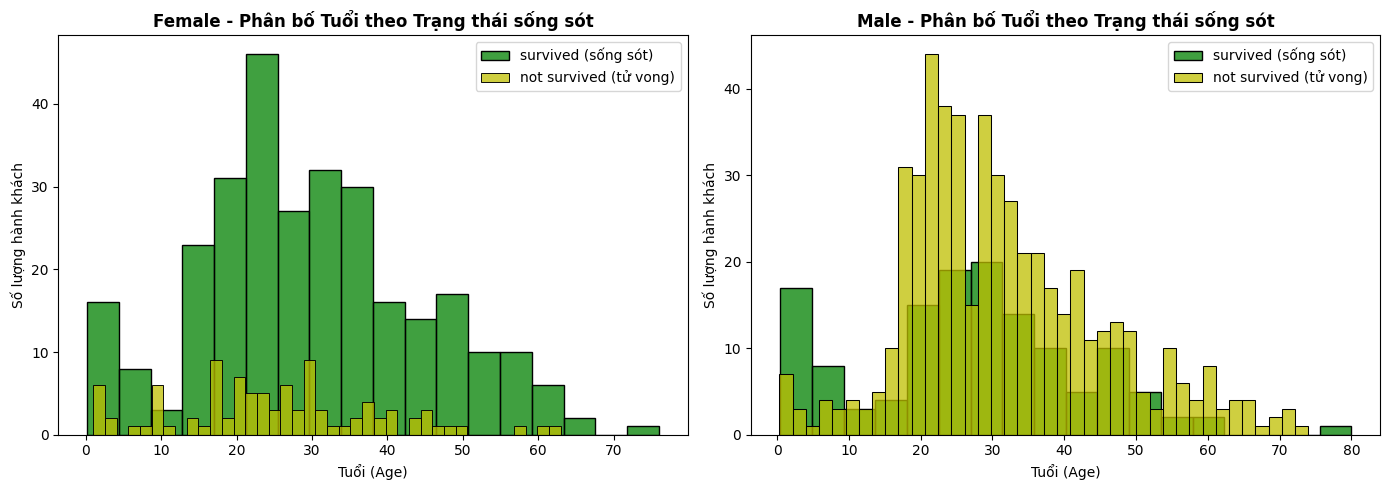

In [3]:
print("Vi Duy Đoàn - 6451071020")
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))

women = df[df['sex'] == 'female']
men = df[df['sex'] == 'male']

# Biểu đồ cho Nữ (Female)
ax0 = sns.histplot(women[women['survived'] == 1]['age'].dropna(), bins=18, label='survived (sống sót)', ax=axes[0], kde=False, color='g')
ax0 = sns.histplot(women[women['survived'] == 0]['age'].dropna(), bins=40, label='not survived (tử vong)', ax=axes[0], kde=False, color='y')
axes[0].legend()
axes[0].set_title('Female - Phân bố Tuổi theo Trạng thái sống sót', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Tuổi (Age)')
axes[0].set_ylabel('Số lượng hành khách')

# Biểu đồ cho Nam (Male)
ax1 = sns.histplot(men[men['survived'] == 1]['age'].dropna(), bins=18, label='survived (sống sót)', ax=axes[1], kde=False, color='g')
ax1 = sns.histplot(men[men['survived'] == 0]['age'].dropna(), bins=40, label='not survived (tử vong)', ax=axes[1], kde=False, color='y')
axes[1].legend()
axes[1].set_title('Male - Phân bố Tuổi theo Trạng thái sống sót', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Tuổi (Age)')
axes[1].set_ylabel('Số lượng hành khách')

plt.tight_layout()
plt.show()


### Nhận xét Câu 3:
1. **Sự khác biệt cực lớn theo Giới tính (Sex):**
   - **Ở Nữ giới:** Cột màu xanh lá đại diện cho người sống sót (`survived = 1`) chiếm tỷ trọng áp đảo ở hầu như mọi độ tuổi. Đặc biệt, phụ nữ trong độ tuổi từ 14 đến 40 tuổi có tỷ lệ sống sót cao vượt trội.
   - **Ở Nam giới:** Ngược lại hoàn toàn, cột màu vàng (`survived = 0`) chiếm đa số tuyệt đối. Nam giới ở độ tuổi thanh niên và trung niên (18 đến 38 tuổi) có số lượng thiệt mạng đông nhất.
2. **Yếu tố Độ tuổi (Age):**
   - **Trẻ em (dưới 5 tuổi):** Cả bé trai lẫn bé gái đều có tỷ lệ sống sót cao hơn so với người lớn cùng giới tính.
   - **Người cao tuổi (trên 65 tuổi):** Số ca sống sót rất hiếm hoi, phần lớn đều không qua khỏi.
3. **Ý nghĩa lịch sử và xã hội:** Biểu đồ phản ánh chân thực quy tắc hàng hải đạo đức thời kỳ Edwardian: *"Women and children first"* (Phụ nữ và trẻ em được ưu tiên lên thuyền cứu sinh trước). Yếu tố giới tính và tuổi tác là hai đặc trưng dự đoán sống sót quan trọng bậc nhất.

## Câu 4: Khảo sát ảnh hưởng của Cảng đón khách, Hạng vé và Tuổi đến Khả năng sống sót
**Yêu cầu:**
- **Ý 1:** Dùng `sns.FacetGrid(df, row='embarked', height=4.5, aspect=1.6)` và `.map(sns.pointplot, 'pclass', 'survived', 'sex', order=[1, 2, 3], hue_order=['female', 'male'])` để khảo sát `embarked`, `pclass`, `survived` theo `sex`.
- **Ý 2:** Vẽ `sns.barplot(x='pclass', y='survived', data=df)`.
- **Ý 3:** Dùng `sns.FacetGrid(df, col='survived', row='pclass', height=4.2, aspect=1.6)` vẽ histogram cột `age` (alpha=0.5, bins=20).
- Viết nhận xét bằng Markdown.

Vi Duy Đoàn - 6451071020


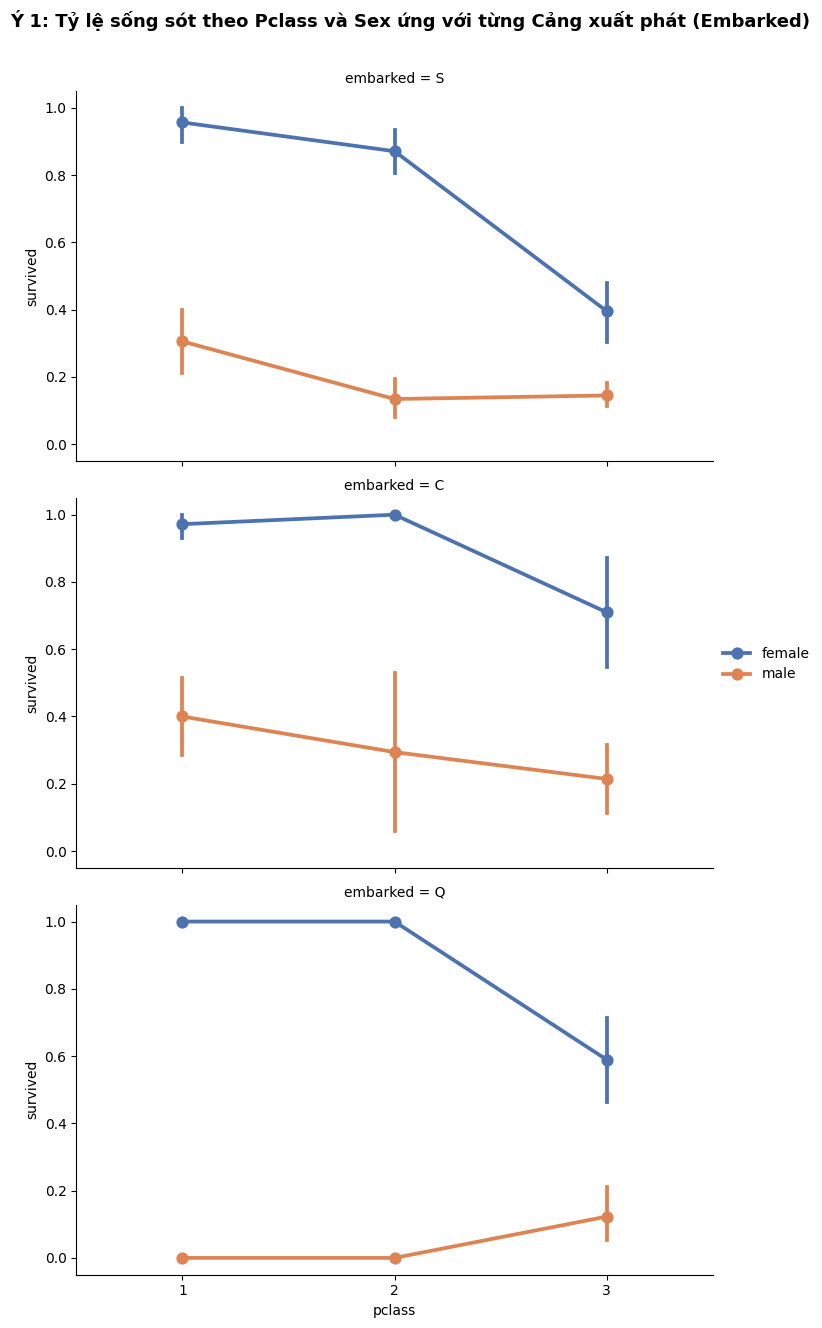

C:\Users\M.S.I\AppData\Local\Temp\ipykernel_13480\478434549.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='pclass', y='survived', data=df, errorbar=None, palette='Blues_d')


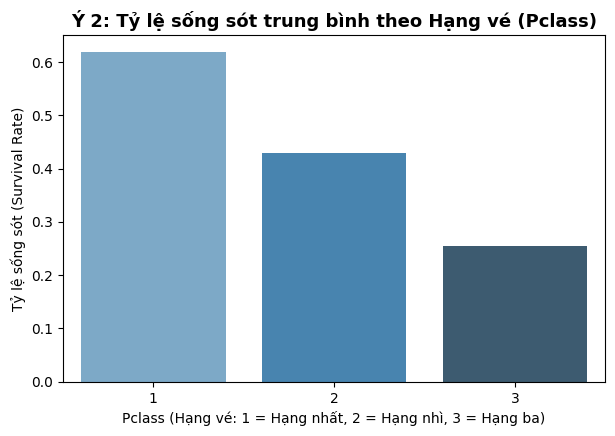

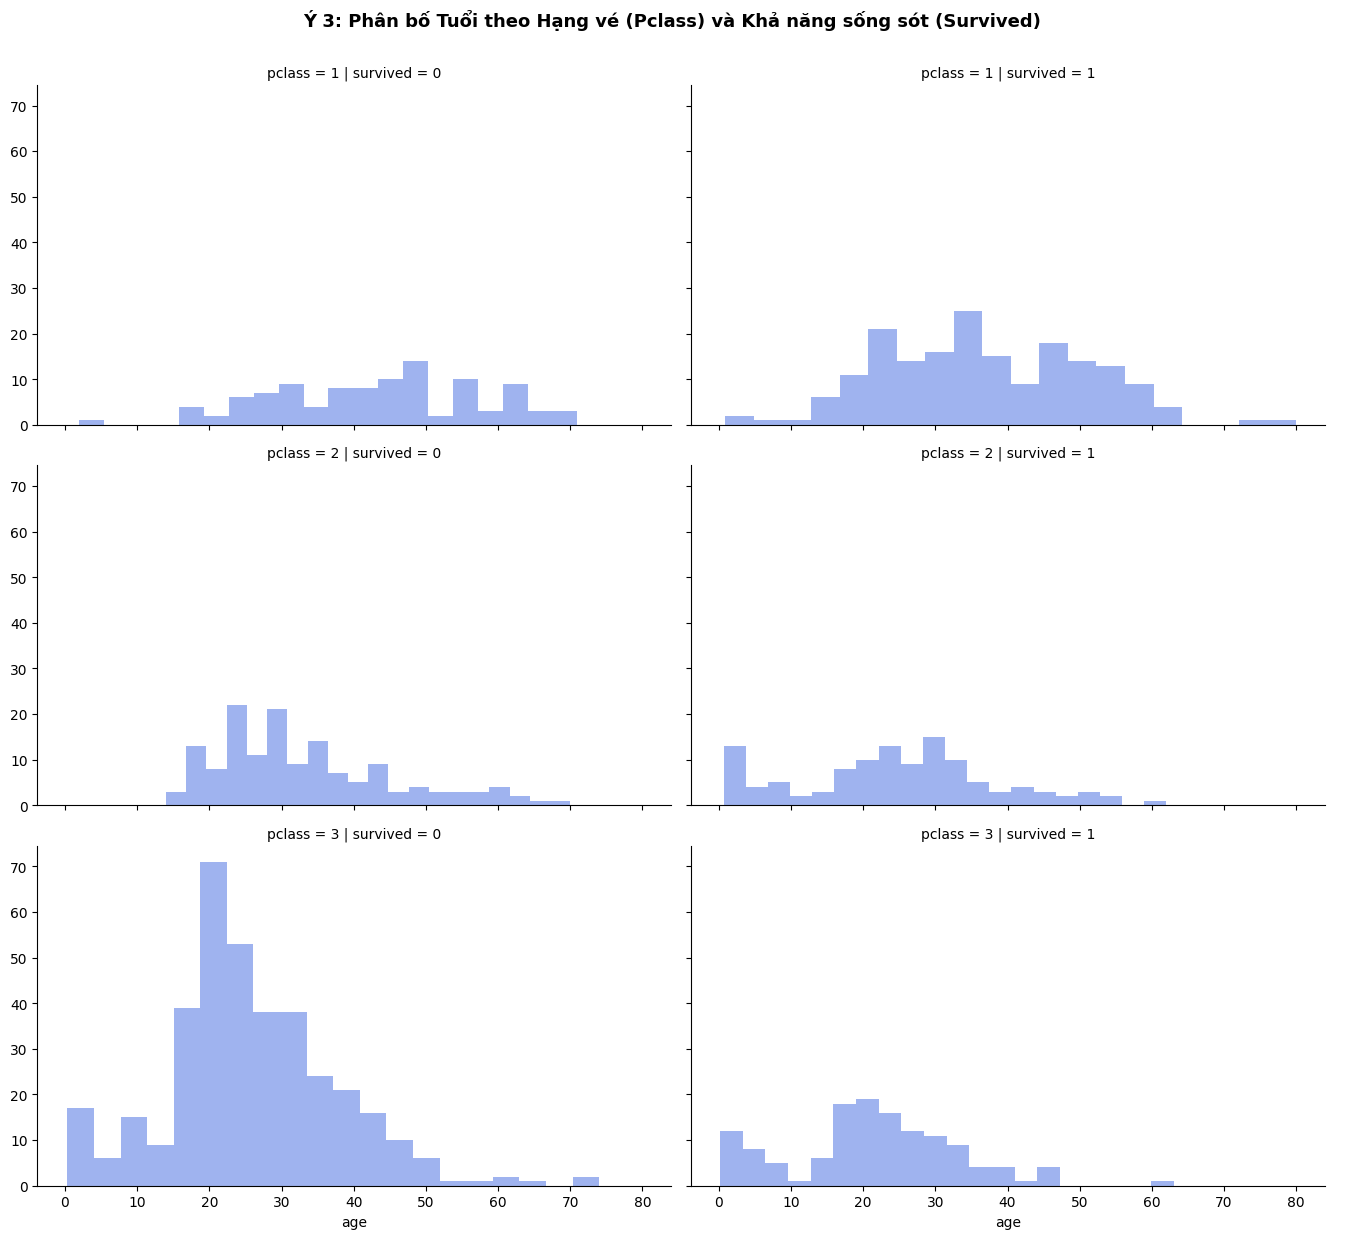

In [4]:
print("Vi Duy Đoàn - 6451071020")
# Ý 1: Khảo sát embarked, pclass, survived theo sex
FacetGrid_emb = sns.FacetGrid(df, row='embarked', height=4.5, aspect=1.6)
FacetGrid_emb.map(sns.pointplot, 'pclass', 'survived', 'sex', order=[1, 2, 3], hue_order=['female', 'male'], palette='deep')
FacetGrid_emb.add_legend()
plt.subplots_adjust(top=0.92)
FacetGrid_emb.figure.suptitle('Ý 1: Tỷ lệ sống sót theo Pclass và Sex ứng với từng Cảng xuất phát (Embarked)', fontsize=13, fontweight='bold')
plt.show()

# Ý 2: Vẽ sns.barplot(x='pclass', y='survived', data=df)
plt.figure(figsize=(7, 4.5))
sns.barplot(x='pclass', y='survived', data=df, errorbar=None, palette='Blues_d')
plt.title('Ý 2: Tỷ lệ sống sót trung bình theo Hạng vé (Pclass)', fontsize=13, fontweight='bold')
plt.xlabel('Pclass (Hạng vé: 1 = Hạng nhất, 2 = Hạng nhì, 3 = Hạng ba)')
plt.ylabel('Tỷ lệ sống sót (Survival Rate)')
plt.show()

# Ý 3: Dùng sns.FacetGrid(df, col='survived', row='pclass', height=4.2, aspect=1.6) vẽ histogram cột age
grid_age_pclass = sns.FacetGrid(df, col='survived', row='pclass', height=4.2, aspect=1.6)
grid_age_pclass.map(plt.hist, 'age', alpha=0.5, bins=20, color='royalblue')
grid_age_pclass.add_legend()
plt.subplots_adjust(top=0.92)
grid_age_pclass.figure.suptitle('Ý 3: Phân bố Tuổi theo Hạng vé (Pclass) và Khả năng sống sót (Survived)', fontsize=13, fontweight='bold')
plt.show()


### Nhận xét Câu 4:
1. **Ý 1 (Mối quan hệ giữa Cảng xuất phát Embarked, Hạng vé Pclass và Giới tính Sex):**
   - Phụ nữ ở hạng 1 và 2 lên tàu từ cảng `S` (Southampton) và `C` (Cherbourg) có tỷ lệ sống sót gần như tuyệt đối (~95% - 100%).
   - Tại cảng `C`, nam giới ở hạng 1 có tỷ lệ sống sót cao hơn rõ rệt so với nam giới lên tàu từ các cảng `S` và `Q`.
   - Tại cảng `Q` (Queenstown), phần lớn hành khách thuộc hạng 3; tỷ lệ sống sót của nam giới ở cảng này là cực kỳ thấp.
2. **Ý 2 (Tỷ lệ sống sót theo Hạng vé Pclass):**
   - Hạng vé thể hiện rõ thứ bậc xã hội và vị trí tầng boong nơi hành khách lưu trú:
     - **Pclass 1 (Hạng nhất):** Tỷ lệ sống sót cao nhất (~**62%**). Do phòng nghỉ nằm ở các tầng trên cùng, gần vị trí thuyền cứu sinh và được hỗ trợ sơ tán trước.
     - **Pclass 2 (Hạng nhì):** Tỷ lệ sống sót đạt mức trung bình (~**43%**).
     - **Pclass 3 (Hạng ba):** Tỷ lệ sống sót thấp nhất (~**26%**). Do các khoang ở tầng đáy tàu, lối đi xa và bị cô lập khi nước tràn vào.
3. **Ý 3 (Phân bố Tuổi theo Hạng vé và Tỷ lệ sống sót):**
   - Ở **Pclass = 1**: Cơ hội sống sót cao trải đều cho nhiều lứa tuổi.
   - Ở **Pclass = 2**: Hầu hết trẻ em đều được cứu sống trọn vẹn.
   - Ở **Pclass = 3**: Chiếm số lượng đông đảo nhất là các thanh niên và người trong độ tuổi lao động (20 - 35 tuổi), và đây cũng chính là nhóm ghi nhận số ca thiệt mạng lớn nhất trong toàn bộ thảm kịch.

## Câu 5: Phân tích Quy mô gia đình (Relatives) và Hành khách đi một mình (Not Alone)
**Yêu cầu:**
- Tạo cột `relatives = df['sibsp'] + df['parch']`.
- Tạo cột `not_alone` (nếu relatives > 0 thì = 0, nếu relatives == 0 thì = 1, kiểu int).
- Thống kê `df['not_alone'].value_counts()`.
- Vẽ biểu đồ `sns.catplot(x='relatives', y='survived', data=df, aspect=2.5, kind='point')`.
- Viết nhận xét bằng Markdown.

Vi Duy Đoàn - 6451071020
=== THỐNG KÊ SỐ LƯỢNG HÀNH KHÁCH THEO THUỘC TÍNH NOT_ALONE ===
1: Đi một mình (Alone) | 0: Đi cùng người thân (Not Alone)
not_alone
1    790
0    519
Name: count, dtype: int64


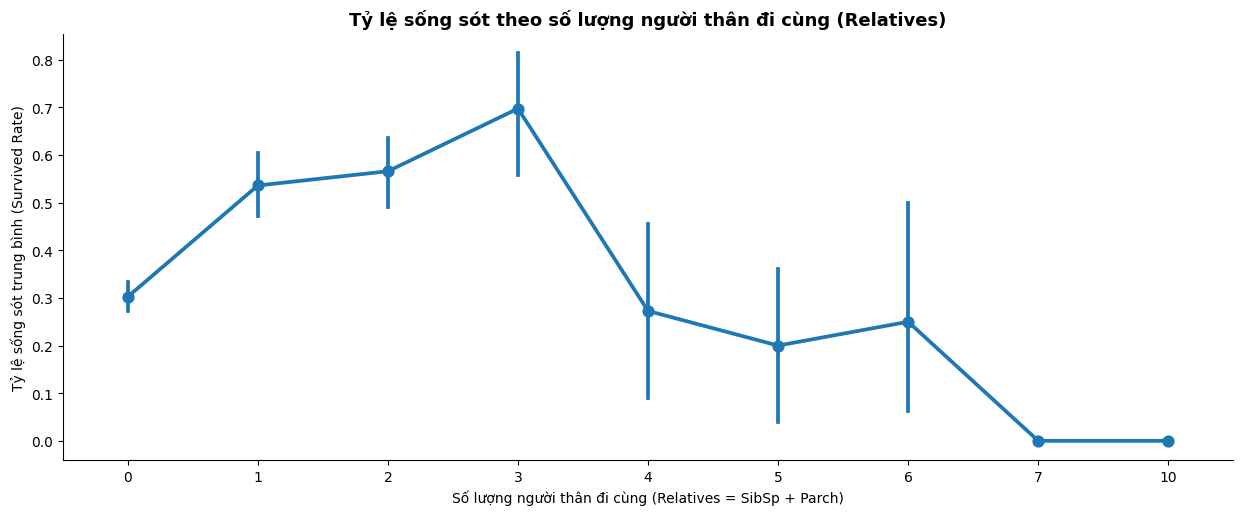

In [5]:
print("Vi Duy Đoàn - 6451071020")
# 1. Tạo cột relatives = sibsp + parch
df['relatives'] = df['sibsp'] + df['parch']

# 2. Tạo cột not_alone: nếu relatives > 0 thì = 0, nếu relatives == 0 thì = 1
df.loc[df['relatives'] > 0, 'not_alone'] = 0
df.loc[df['relatives'] == 0, 'not_alone'] = 1
df['not_alone'] = df['not_alone'].astype(int)

# 3. Thống kê df['not_alone'].value_counts()
print("=== THỐNG KÊ SỐ LƯỢNG HÀNH KHÁCH THEO THUỘC TÍNH NOT_ALONE ===")
print("1: Đi một mình (Alone) | 0: Đi cùng người thân (Not Alone)")
print(df['not_alone'].value_counts())

# 4. Vẽ biểu đồ sns.catplot
axes_rel = sns.catplot(x='relatives', y='survived', data=df, aspect=2.5, kind='point')
plt.title('Tỷ lệ sống sót theo số lượng người thân đi cùng (Relatives)', fontsize=13, fontweight='bold')
plt.xlabel('Số lượng người thân đi cùng (Relatives = SibSp + Parch)')
plt.ylabel('Tỷ lệ sống sót trung bình (Survived Rate)')
plt.show()


### Nhận xét Câu 5:
1. **Phân bố khách đi một mình vs đi cùng người thân:**
   - Số người đi một mình (`not_alone = 1`) là **790 người** (chiếm hơn 60% tổng số hành khách).
   - Số người đi cùng gia đình/người thân (`not_alone = 0`) là **519 người** (chiếm gần 40%).
2. **Quy mô gia đình ảnh hưởng đến khả năng sống sót:**
   - **Người đi một mình (`relatives = 0`):** Tỷ lệ sống sót chỉ khoảng **30%**, tương đối thấp do không có người hỗ trợ chia sẻ thông tin hoặc giúp đỡ trong lúc hoảng loạn.
   - **Gia đình quy mô nhỏ (1 đến 3 người thân):** Tỷ lệ sống sót tăng vọt lên mức cao nhất, dao động từ **50% đến trên 70%** (đạt đỉnh tại `relatives = 3`). Nhóm nhỏ giúp các thành viên dễ chăm sóc, hỗ trợ nhau tìm kiếm lối thoát hiểm.
   - **Gia đình quy mô lớn (`relatives >= 4` người):** Tỷ lệ sống sót giảm dốc đứng xuống dưới 20%. Lý do là trong hoàn cảnh hỗn loạn, gia đình đông người rất khó khăn trong việc tìm kiếm, tập hợp tất cả thành viên trước khi lên xuồng cứu sinh.

## Câu 6: Tiền xử lý dữ liệu thiếu và loại bỏ các cột không cần thiết
**Yêu cầu:**
- Điền `'U0'` cho các giá trị thiếu của cột `cabin`, dùng Regex trích xuất chữ cái đầu tạo cột `deck`, ánh xạ `{"A": 1, "B": 2, "C": 3, "D": 4, "E": 5, "F": 6, "G": 7, "U": 8}`, điền 0 cho NaN và ép kiểu `int`, sau đó xóa cột `cabin`.
- Xóa các cột `ticket`, `boat`, `body`, `home.dest` (dùng `errors='ignore'`).
- Điền giá trị thiếu cho cột `age` bằng số nguyên ngẫu nhiên trong khoảng `[mean - std, mean + std]`, ép kiểu `age` về `int`.
- Điền giá trị thiếu cho cột `embarked` bằng giá trị phổ biến nhất (`'S'`).
- Viết nhận xét bằng Markdown.

In [6]:
print("Vi Duy Đoàn - 6451071020")
import re

# 1. Xử lý cột cabin: điền 'U0', trích xuất deck, ánh xạ sang số, điền 0 cho NaN, ép kiểu int, xóa cột cabin
deck_mapping = {"A": 1, "B": 2, "C": 3, "D": 4, "E": 5, "F": 6, "G": 7, "U": 8}
df['cabin'] = df['cabin'].fillna("U0")
df['deck'] = df['cabin'].map(lambda x: re.compile("([a-zA-Z]+)").search(x).group())
df['deck'] = df['deck'].map(deck_mapping)
df['deck'] = df['deck'].fillna(0)
df['deck'] = df['deck'].astype(int)
df = df.drop(['cabin'], axis=1)

# 2. Xóa các cột ticket, boat, body, home.dest
df = df.drop(['ticket', 'boat', 'body', 'home.dest'], axis=1, errors='ignore')

# 3. Điền giá trị thiếu cho cột age bằng số nguyên ngẫu nhiên trong khoảng [mean - std, mean + std]
np.random.seed(42)  # Cố định seed ngẫu nhiên
mean_age = df["age"].mean()
std_age = df["age"].std()
is_null_age = df["age"].isnull().sum()

# Sinh các số nguyên ngẫu nhiên trong khoảng [mean - std, mean + std]
rand_age = np.random.randint(int(mean_age - std_age), int(mean_age + std_age) + 1, size=is_null_age)

# Điền vào các giá trị NaN của cột age
age_slice = df["age"].copy()
age_slice[np.isnan(age_slice)] = rand_age
df["age"] = age_slice
df["age"] = df["age"].astype(int)

# 4. Điền giá trị thiếu cho cột embarked bằng giá trị phổ biến nhất ('S')
df['embarked'] = df['embarked'].fillna('S')

# Kiểm tra lại số lượng giá trị rỗng sau tiền xử lý
print("=== SỐ LƯỢNG GIÁ TRỊ RỖNG CÒN LẠI SAU TIỀN XỬ LÝ ===")
print(df.isnull().sum())
print("\n5 dòng đầu tiên sau khi xử lý:")
display(df.head(5))


Vi Duy Đoàn - 6451071020
=== SỐ LƯỢNG GIÁ TRỊ RỖNG CÒN LẠI SAU TIỀN XỬ LÝ ===
pclass       0
survived     0
name         0
sex          0
age          0
sibsp        0
parch        0
fare         1
embarked     0
relatives    0
not_alone    0
deck         0
dtype: int64

5 dòng đầu tiên sau khi xử lý:


,pclass,survived,name,sex,age,sibsp,parch,fare,embarked,relatives,not_alone,deck
0,1,1,"Allen, Miss. Elisabeth Walton",female,29,0,0,211.3375,S,0,1,2
1,1,1,"Allison, Master. Hudson Trevor",male,0,1,2,151.5500,S,3,0,3
2,1,0,"Allison, Miss. Helen Loraine",female,2,1,2,151.5500,S,3,0,3
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30,1,2,151.5500,S,3,0,3
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25,1,2,151.5500,S,3,0,3


### Nhận xét Câu 6:
1. **Biến đổi `cabin` thành `deck`:**
   - Ký tự chữ cái đầu tiên của phòng thể hiện vị trí tầng boong tàu (từ boong trên A, B, C xuống các boong dưới E, F, G).
   - Việc gán `U0` (Unknown) đại diện cho nhóm 8 giúp tận dụng được thông tin vị trí phòng của hành khách mà không phải xóa bỏ cả hàng dữ liệu.
2. **Loại bỏ các thuộc tính gây nhiễu và rò rỉ dữ liệu:**
   - `ticket` và `home.dest`: Có độ phân tán quá lớn, dạng chuỗi văn bản tự do không mang tính quy luật chung.
   - `boat` và `body`: Là dữ liệu thu thập sau thảm họa (target leakage). Nếu đưa vào mô hình học máy sẽ dẫn đến đánh giá sai lệch hiệu năng thực tế.
3. **Kỹ thuật điền giá trị thiếu cho thuộc tính `age`:**
   - Thay vì dùng một giá trị cố định (như trung vị hoặc giá trị trung bình sẽ làm giảm độ biến thiên và thu hẹp phân phối), phương pháp sinh số ngẫu nhiên trong khoảng $[\mu - \sigma, \mu + \sigma]$ giúp duy trì hình dạng phân phối chuẩn ban đầu của biến tuổi.
4. **Điền giá trị thiếu cho `embarked`:**
   - Cảng Southampton (`S`) có số lượng khách lên tàu áp đảo (hơn 70%), do đó việc gán giá trị phổ biến nhất (`mode`) cho 2 mẫu bị thiếu là giải pháp chuẩn xác và tự nhiên nhất.

## Câu 7: Biến đổi và mã hóa các thuộc tính (Feature Transformation & Encoding)
**Yêu cầu:**
- **Cột `fare`:** `fillna(0)`. Chia `fare` thành 6 nhóm: `<= 7.91` -> 0; `(7.91, 14.454]` -> 1; `(14.454, 31]` -> 2; `(31, 99]` -> 3; `(99, 250]` -> 4; `> 250` -> 5. Sau đó ép kiểu `fare` về `int`.
- **Cột `name`:** Trích xuất `title` bằng regex `' ([A-Za-z]+)\.'`, gộp các danh hiệu hiếm `['Lady', 'Countess','Capt', 'Col','Don', 'Dr', 'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona']` thành `'Rare'`, đổi `'Mlle'`, `'Ms'` thành `'Miss'`, `'Mme'` thành `'Mrs'`. Ánh xạ `{"Mr": 1, "Miss": 2, "Mrs": 3, "Master": 4, "Rare": 5}`, `fillna(0)` rồi xóa cột `name`.
- **Cột `sex`:** Ánh xạ `{"male": 0, "female": 1}`.
- **Cột `embarked`:** Ánh xạ `{"S": 0, "C": 1, "Q": 2}`.
- **Cột `age`:** Chia thành 8 nhóm: `<= 11` -> 0; `(11, 18]` -> 1; `(18, 22]` -> 2; `(22, 27]` -> 3; `(27, 33]` -> 4; `(33, 40]` -> 5; `(40, 66]` -> 6; `> 66` -> 7. In ra `df['age'].value_counts()`.
- Viết nhận xét bằng Markdown.

In [7]:
print("Vi Duy Đoàn - 6451071020")
# 1. Cột fare: fillna(0), chia thành 6 nhóm trước khi ép kiểu int
df['fare'] = df['fare'].fillna(0)
df.loc[df['fare'] <= 7.91, 'fare'] = 0
df.loc[(df['fare'] > 7.91) & (df['fare'] <= 14.454), 'fare'] = 1
df.loc[(df['fare'] > 14.454) & (df['fare'] <= 31.0), 'fare'] = 2
df.loc[(df['fare'] > 31.0) & (df['fare'] <= 99.0), 'fare'] = 3
df.loc[(df['fare'] > 99.0) & (df['fare'] <= 250.0), 'fare'] = 4
df.loc[df['fare'] > 250.0, 'fare'] = 5
df['fare'] = df['fare'].astype(int)

# 2. Cột name: trích xuất title bằng regex, gộp danh hiệu hiếm, chuẩn hóa và ánh xạ sang số
df['title'] = df['name'].str.extract(r' ([A-Za-z]+)\.', expand=False)
rare_titles = ['Lady', 'Countess','Capt', 'Col','Don', 'Dr', 'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona']
df['title'] = df['title'].replace(rare_titles, 'Rare')
df['title'] = df['title'].replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})

titles_mapping = {"Mr": 1, "Miss": 2, "Mrs": 3, "Master": 4, "Rare": 5}
df['title'] = df['title'].map(titles_mapping)
df['title'] = df['title'].fillna(0)
df['title'] = df['title'].astype(int)
df = df.drop(['name'], axis=1)

# 3. Cột sex: Ánh xạ male -> 0, female -> 1
df['sex'] = df['sex'].map({'male': 0, 'female': 1})

# 4. Cột embarked: Ánh xạ S -> 0, C -> 1, Q -> 2
df['embarked'] = df['embarked'].map({'S': 0, 'C': 1, 'Q': 2})

# 5. Cột age: Chia thành 8 nhóm và ép kiểu int
df.loc[df['age'] <= 11, 'age'] = 0
df.loc[(df['age'] > 11) & (df['age'] <= 18), 'age'] = 1
df.loc[(df['age'] > 18) & (df['age'] <= 22), 'age'] = 2
df.loc[(df['age'] > 22) & (df['age'] <= 27), 'age'] = 3
df.loc[(df['age'] > 27) & (df['age'] <= 33), 'age'] = 4
df.loc[(df['age'] > 33) & (df['age'] <= 40), 'age'] = 5
df.loc[(df['age'] > 40) & (df['age'] <= 66), 'age'] = 6
df.loc[df['age'] > 66, 'age'] = 7
df['age'] = df['age'].astype(int)

# In kết quả thống kê nhóm tuổi
print("=== THỐNG KÊ SỐ LƯỢNG HÀNH KHÁCH THEO 8 NHÓM TUỔI (df['age'].value_counts()) ===")
print(df['age'].value_counts().sort_index())


Vi Duy Đoàn - 6451071020
=== THỐNG KÊ SỐ LƯỢNG HÀNH KHÁCH THEO 8 NHÓM TUỔI (df['age'].value_counts()) ===
age
0     91
1    140
2    174
3    213
4    219
5    199
6    264
7      9
Name: count, dtype: int64


### Nhận xét Câu 7:
1. **Phân nhóm giá vé (`fare`):** Việc rời rạc hóa (discretization/binning) giá vé thành 6 mức dựa trên các tứ phân vị giúp loại trừ triệt để ảnh hưởng của các giá trị ngoại lai (outliers giá vé cực cao) mà vẫn phản ánh trung thực mức độ sang trọng của vé.
2. **Khai phá thông tin từ họ tên (`title`):** Cột họ tên ban đầu có vẻ là văn bản thuần túy, nhưng việc bóc tách danh xưng (`Mr`, `Miss`, `Mrs`, `Master`, `Rare`) cung cấp thuộc tính đại diện cho cả giới tính, độ tuổi và tầng lớp xã hội (ví dụ: `Master` luôn là bé trai, `Mrs` là phụ nữ có gia đình, `Rare` là quý tộc hoặc sĩ quan).
3. **Mã hóa các thuộc tính danh mục (`sex`, `embarked`):** Đã được chuyển đổi sang dạng số nguyên nhị phân / số nguyên thứ tự (`0, 1` cho giới tính; `0, 1, 2` cho cảng xuất phát), hoàn toàn tương thích với các thuật toán học máy.
4. **Phân nhóm độ tuổi (`age`):** Chia nhỏ thành 8 nhóm giúp các mô hình phân loại dễ dàng nắm bắt các ranh giới quyết định phi tuyến tính giữa các thế hệ tuổi (trẻ em, thanh niên, trung niên, người già).

## Câu 8: Xây dựng các thuộc tính mới (Feature Engineering) và Hoàn thiện bộ dữ liệu
**Yêu cầu:**
- Tạo cột `df['age_class'] = df['age'] * df['pclass']`.
- Tạo cột `df['fare_per_person'] = (df['fare'] / (df['relatives'] + 1)).astype(int)`.
- Hiển thị `df.head(10)`.
- Viết nhận xét bằng Markdown.

In [8]:
print("Vi Duy Đoàn - 6451071020")
# 1. Tạo thuộc tính tương tác age_class
df['age_class'] = df['age'] * df['pclass']

# 2. Tạo thuộc tính giá vé trung bình mỗi người fare_per_person
df['fare_per_person'] = (df['fare'] / (df['relatives'] + 1)).astype(int)

# 3. Hiển thị 10 dòng đầu tiên
print("=== 10 DÒNG ĐẦU TIÊN CỦA BỘ DỮ LIỆU HOÀN THIỆN (df.head(10)) ===")
display(df.head(10))

# 4. Kiểm tra tổng quan toàn bộ tập dữ liệu sau cùng
print("\n=== THÔNG TIN TỔNG QUAN TẬP DỮ LIỆU SAU CÙNG (df.info()) ===")
df.info()


Vi Duy Đoàn - 6451071020
=== 10 DÒNG ĐẦU TIÊN CỦA BỘ DỮ LIỆU HOÀN THIỆN (df.head(10)) ===


,pclass,survived,sex,age,sibsp,parch,fare,embarked,relatives,not_alone,deck,title,age_class,fare_per_person
0,1,1,1,4,0,0,4,0,0,1,2,2,4,4
1,1,1,0,0,1,2,4,0,3,0,3,4,0,1
2,1,0,1,0,1,2,4,0,3,0,3,2,0,1
3,1,0,0,4,1,2,4,0,3,0,3,1,4,1
4,1,0,1,3,1,2,4,0,3,0,3,3,3,1
5,1,1,0,6,0,0,2,0,0,1,5,1,6,2
6,1,1,1,6,1,0,3,0,1,0,4,2,6,1
7,1,0,0,5,0,0,0,0,0,1,1,1,5,0
8,1,1,1,6,2,0,3,0,2,0,3,3,6,1
9,1,0,0,7,0,0,3,1,0,1,8,1,7,3



=== THÔNG TIN TỔNG QUAN TẬP DỮ LIỆU SAU CÙNG (df.info()) ===
<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   pclass           1309 non-null   int64
 1   survived         1309 non-null   int64
 2   sex              1309 non-null   int64
 3   age              1309 non-null   int64
 4   sibsp            1309 non-null   int64
 5   parch            1309 non-null   int64
 6   fare             1309 non-null   int64
 7   embarked         1309 non-null   int64
 8   relatives        1309 non-null   int64
 9   not_alone        1309 non-null   int64
 10  deck             1309 non-null   int64
 11  title            1309 non-null   int64
 12  age_class        1309 non-null   int64
 13  fare_per_person  1309 non-null   int64
dtypes: int64(14)
memory usage: 143.3 KB


### Nhận xét Câu 8:
1. **Ý nghĩa của 2 thuộc tính mới:**
   - **`age_class = age * pclass`:** Đây là thuộc tính kết hợp tương tác giữa hai yếu tố quan trọng nhất là Tuổi và Hạng vé. Giá trị tích số này phân tách rất tốt: người có `age_class` nhỏ (trẻ em hoặc người ở hạng 1) có cơ hội sống sót rất cao; ngược lại người có `age_class` lớn (người cao tuổi ở hạng 3) có tỷ lệ sống sót thấp nhất.
   - **`fare_per_person = fare / (relatives + 1)`:** Giá vé tính trên đầu người giúp phản ánh chính xác khả năng tài chính thực tế của từng cá nhân khi mua vé theo đoàn gia đình.
2. **Tổng kết toàn bộ quy trình tiền xử lý Lab 1:**
   - Tập dữ liệu Titanic sau tiền xử lý gồm **1309 dòng** và **14 cột thuộc tính**.
   - **100% các cột đều ở dạng số nguyên (`int64`)**, hoàn toàn không còn dữ liệu văn bản thuần túy.
   - **Không còn bất kỳ giá trị thiếu (`null`)** nào trên toàn bộ tập dữ liệu.
   - Bộ dữ liệu đã đạt chuẩn chất lượng cao, sẵn sàng để áp dụng trực tiếp vào các mô hình phân lớp và dự đoán của môn học Khai phá dữ liệu (Decision Tree, Random Forest, Logistic Regression, v.v.).